# Image Classification 


Using fmnist dataset


In [1]:
import tensorflow as tf 
import numpy as np 
import matplotlib.pyplot as plt


I0000 00:00:1777080296.472154     912 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1777080297.568229     912 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1777080300.537375     912 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
df = tf.keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 21s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 3s 1us/step


In [10]:
print("Shape of training images:", df[0][0].shape)
print("Shape of training labels:", df[0][1].shape)
print("Shape of testing images:", df[1][0].shape)
print("Shape of testing labels:", df[1][1].shape)


Shape of training images: (60000, 28, 28)
Shape of training labels: (60000,)
Shape of testing images: (10000, 28, 28)
Shape of testing labels: (10000,)


In [45]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [11]:
# separating the data 
X_train, y_train = df[0]
X_test, y_test = df[1]

# or 
# (X_train, y_train), (X_test, y_test) = df

In [12]:
X_train

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [13]:
X_test

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [14]:
y_train

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

In [15]:
y_test

array([9, 2, 1, ..., 8, 1, 5], shape=(10000,), dtype=uint8)

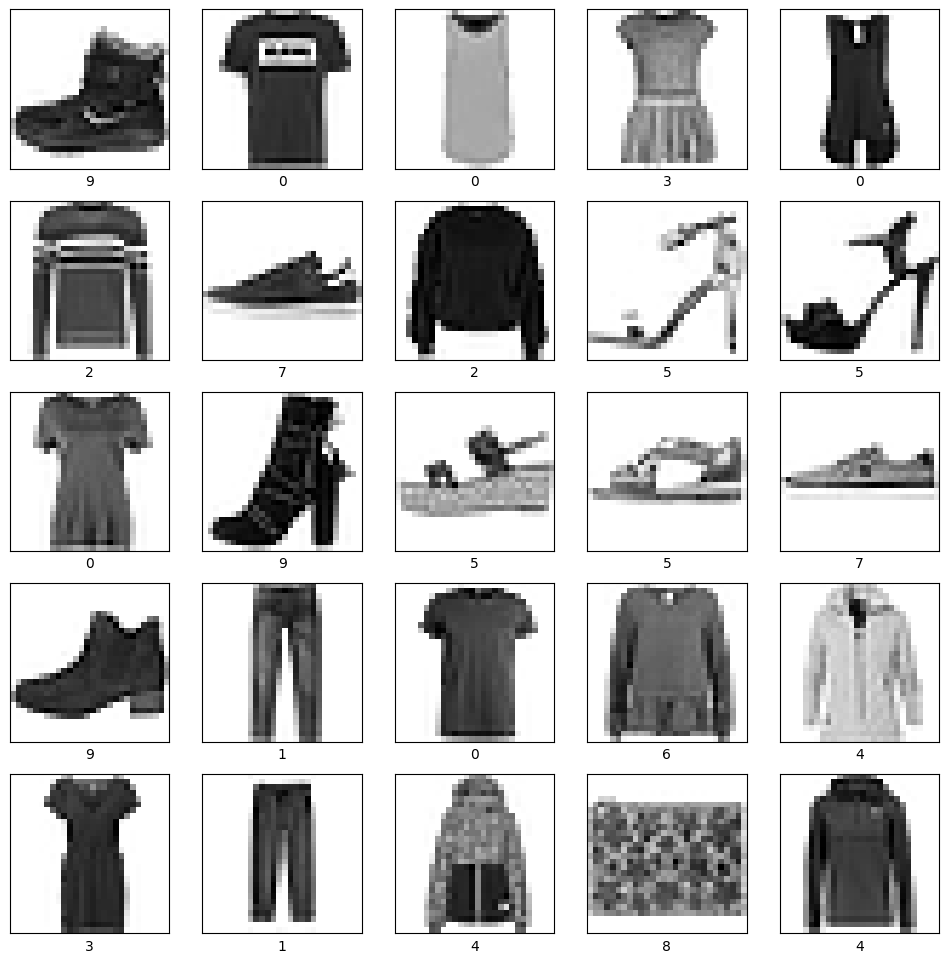

In [37]:

plt.figure(figsize=(12, 12))

for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    # plt.grid(False)
    plt.imshow(X_train[i]  , cmap=plt.cm.binary)
    plt.xlabel(y_train[i])

plt.show()

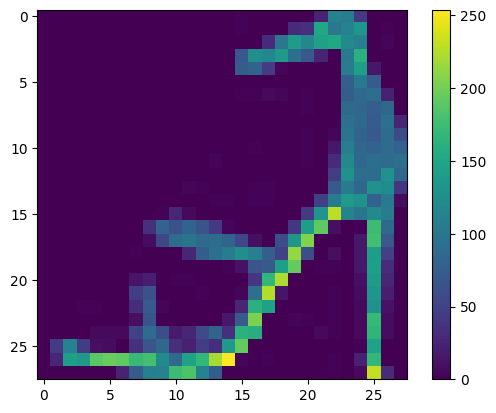

In [46]:
plt.imshow(X_train[899])
plt.colorbar()

In [49]:
print("Pixel values : ") 
for row in X_train[899]:
    for pixel in row:
        print("{:3}".format(pixel), end=" ")
    print()

Pixel values : 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   2   0   0   0   0   0  25 113 107  42   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   2   0   0   0  31  35 151 101 113 134   0   2   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  31 101 139 118 145 151 122 111   0   4   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  69 126 118 136  94  71  25   0 105 162   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  75  82  44   4   0   0   0   0 107 143  16   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  77 103  73   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   2   2   6   4   0   2   0   0  75  88  92  23   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   2   0   0  88  84  77  86   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 

In [55]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [56]:
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

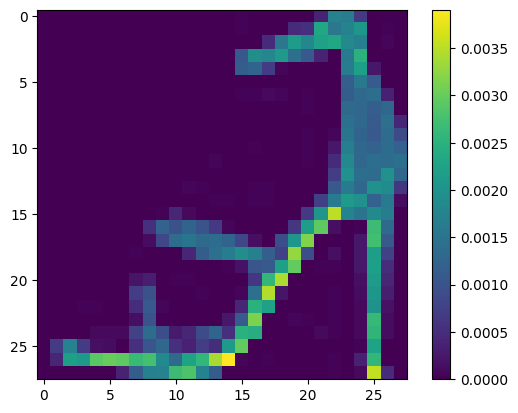

In [57]:
plt.imshow(X_train[899])
plt.colorbar()

In [58]:
print("Pixel values : ") 
for row in X_train[899]:
    for pixel in row:
        print("{:0.3}".format(pixel), end=" ")
    print()

Pixel values : 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 3.08e-05 0.0 0.0 0.0 0.0 0.0 0.000384 0.00174 0.00165 0.000646 0.0 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 3.08e-05 0.0 0.0 0.0 0.000477 0.000538 0.00232 0.00155 0.00174 0.00206 0.0 3.08e-05 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.000477 0.00155 0.00214 0.00181 0.00223 0.00232 0.00188 0.00171 0.0 6.15e-05 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00106 0.00194 0.00181 0.00209 0.00145 0.00109 0.000384 0.0 0.00161 0.00249 0.0 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00115 0.00126 0.000677 6.15e-05 0.0 0.0 0.0 0.0 0.00165 0.0022 0.000246 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00118 0.00158 0.00112 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 3.08e-05 3.08e-05 9.23e-05 6.15e-05 0.0 3.08e-05 0.0 0.0 0.00115 0.001

In [59]:
# Reshape the images

X_train = X_train.reshape(X_train.shape[0], 28, 28, 1)
X_test = X_test.reshape(X_test.shape[0], 28, 28, 1)

In [66]:
# creating the model 


input_layer = tf.keras.layers.Input(shape=(28 , 28 , 1))

model = tf.keras.Sequential([
    input_layer , 
tf.keras.layers.Conv2D(filters=32 , kernel_size=(3,3)  , activation="relu") ,
tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
tf.keras.layers.Flatten(),
tf.keras.layers.Dense(10 , activation="softmax")
])

W0000 00:00:1777082940.541126     912 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1777082940.548225     912 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1777082940.843174     912 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5174 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


In [67]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        54,090 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,410 (212.54 KB)

 Trainable params: 54,410 (212.54 KB)

 Non-trainable params: 0 (0.00 B)

### Filters & Kernel Size (in this model)

- **Conv2D(filters=32, kernel_size=(3,3))**
  - **Filters = 32** → model learns 32 different feature maps (edges, shapes, patterns)
  - **Kernel size = (3×3)** → looks at small local regions of the image

 

### Effect of changing values

- **Increase filters (e.g., 64, 128)**
  - Learns more complex features
  - Improves accuracy (usually)
  - Increases computation

- **Change kernel size**
  - **(5×5)** → captures larger patterns, output shrinks more
  - **(3×3)** → balanced (most common)
  - **(1×1)** → focuses on channel-wise features

 

`  In short:`
- Filters = *how many features*  
- Kernel size = *how big area each feature looks at*


In [73]:
# creating the model 


input_layer = tf.keras.layers.Input(shape=(28 , 28 , 1))

model = tf.keras.Sequential([
        input_layer , 
    tf.keras.layers.Conv2D(filters=32 , kernel_size=(3,3)  , activation="relu") ,
    tf.keras.layers.MaxPooling2D(pool_size=(3,3)),
    tf.keras.layers.Conv2D(filters=64 , kernel_size=(3,3) , activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(10 , activation="softmax")
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 6, 6, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,770 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,586 (96.04 KB)

 Trainable params: 24,586 (96.04 KB)

 Non-trainable params: 0 (0.00 B)

In [74]:
# compile the model
model.compile(optimizer="adam" , loss="sparse_categorical_crossentropy" , metrics=["accuracy"])

In [75]:
# train the model
model.fit(X_train, y_train , epochs=10 , batch_size=32 , validation_split=0.2)

Epoch 1/10


I0000 00:00:1777084470.451798    8130 service.cc:153] XLA service 0x7f4cfc030910 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777084470.451975    8130 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5050 Laptop GPU, Compute Capability 12.0a (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.0)
I0000 00:00:1777084470.549709    8130 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1777084470.831568    8130 cuda_dnn.cc:461] Loaded cuDNN version 92100
I0000 00:00:1777084470.866401    8130 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1433__.29


  19/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.1073 - loss: 2.3029 

I0000 00:00:1777084478.207612    8130 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 11ms/step - accuracy: 0.5877 - loss: 1.2073 - val_accuracy: 0.7297 - val_loss: 0.7610
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.7335 - loss: 0.7352 - val_accuracy: 0.7500 - val_loss: 0.6894
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.7541 - loss: 0.6788 - val_accuracy: 0.7677 - val_loss: 0.6429
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.7678 - loss: 0.6423 - val_accuracy: 0.7735 - val_loss: 0.6215
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.7782 - loss: 0.6120 - val_accuracy: 0.7871 - val_loss: 0.5888
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.7880 - loss: 0.5878 - val_accuracy: 0.7976 - val_loss: 0.5638
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.7947 - loss: 0.5662 - val_accuracy: 0.7980 - val_loss: 0.5490
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.8023 - loss: 0.5484 -

In [76]:
# model evaluation 
test_loss , test_accuracy  = model.evaluate(X_test , y_test) 

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8095 - loss: 0.5306


In [78]:
print("test loss :" , test_loss)
print("test accuracy :" , test_accuracy)


test loss : 0.5305949449539185
test accuracy : 0.809499979019165


In [80]:
# save the model 
model.save('models/fashion_mnist_cnn_model.h5')

### Make predictions


In [81]:
predictions = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step


In [82]:
predictions[0]

array([2.0695568e-08, 9.8896100e-11, 7.2725709e-07, 8.6475518e-07,
       2.2548591e-07, 7.7188149e-02, 1.4980229e-07, 4.4893706e-01,
       1.3558852e-03, 4.7251692e-01], dtype=float32)

In [85]:
y_test[0] 

np.uint8(9)

In [86]:
np.argmax(predictions[0])

np.int64(9)

## Evaluation with confusion matrix 

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


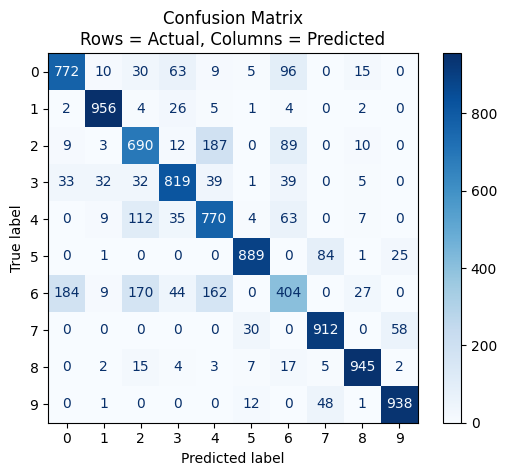

In [87]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# Get predictions (probabilities → class index)
y_pred = model.predict(X_test)
y_pred = np.argmax(y_pred, axis=1)

# If your y_test is one-hot encoded, convert it
if len(y_test.shape) > 1:
    y_true = np.argmax(y_test, axis=1)
else:
    y_true = y_test

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display it
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

plt.title("Confusion Matrix\nRows = Actual, Columns = Predicted")
plt.show()


### Confusion Matrix Interpretation

- The diagonal values represent **correct predictions**. Most classes have high values (700–950 range), showing good overall performance of the model.

- The instructor’s point:  
   **Off-diagonal values (errors) should ideally not be in three digits**  
  - Here, some errors are quite high (e.g., 184, 170, 162), indicating **significant confusion between certain classes**.

 

### Key Observations

- **Class 1, 7, 8, 9**  
  - Very high correct predictions (956, 912, 945, 938)  
  -  These classes are **well learned**

- **Class 6 (weak performance)**  
  - Only **404 correct predictions**
  - High confusion with:
    - Class 0 → 184
    - Class 2 → 170
    - Class 4 → 162  
  - Model struggles to distinguish this class

- **Class 2 and 4 confusion**
  - Class 2 → predicted as 4 = 187  
  - Class 4 → predicted as 2 = 112  
  -  These two classes are **visually similar**

- **Class 5 and 7 confusion**
  - Class 5 → predicted as 7 = 84  
  - Class 7 → predicted as 5 = 30  
  -  Moderate confusion between them

 

### Overall Insight

- The model performs well on **distinct classes**
- Errors increase when classes are **visually similar**
- Presence of **3-digit off-diagonal values** suggests:
  - Need for **better feature extraction**
  - Or **model tuning (more layers / filters / data augmentation)**
 


 ### How to Improve the Model

- **Increase Epochs**
  - Train longer (e.g., from 5 → 15–25 epochs)
  - Helps the model learn better patterns

- **Add More Convolution Layers**
  - Use deeper architecture:
    - Conv → Conv → Pool instead of single Conv
  - Improves feature extraction

- **Increase Filters**
  - Example: 32 → 64 → 128
  - Learns more complex patterns

- **Use Dropout**
  - Add `Dropout(0.3–0.5)`
  - Reduces overfitting

- **Data Augmentation**
  - Slight rotations, shifts, flips
  - Helps model generalize better

- **Tune Kernel Size**
  - Try combination: (3×3) + (5×5)
  - Capture both small and large features

- **Normalize Properly**
  - Ensure input is scaled (already done: `/255.0`)

- **Use Batch Normalization**
  - Stabilizes and speeds up training

- **Adjust Learning Rate**
  - Lower learning rate (e.g., 0.001 → 0.0005)
  - More stable learning

---

 


### Final Conclusion

 Good overall accuracy, but  
 Certain classes need improvement due to **high misclassification (3-digit errors)**  


## Stopping using Callbacks 


I am also increasing the number of epochs here to have more accuracy 

Epoch 1/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 25s 13ms/step - accuracy: 0.8640 - loss: 0.3712 - val_accuracy: 0.8569 - val_loss: 0.3994
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.8646 - loss: 0.3688 - val_accuracy: 0.8579 - val_loss: 0.3996
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8667 - loss: 0.3650 - val_accuracy: 0.8571 - val_loss: 0.3952
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 25s 13ms/step - accuracy: 0.8671 - loss: 0.3632 - val_accuracy: 0.8575 - val_loss: 0.3948
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.8686 - loss: 0.3601 - val_accuracy: 0.8551 - val_loss: 0.3966
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8694 - loss: 0.3578 - val_accuracy: 0.8600 - val_loss: 0.3893
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8707 - loss: 0.3546 - val_accuracy: 0.8590 - val_loss: 0.3922
Epoch 8/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.8722 -

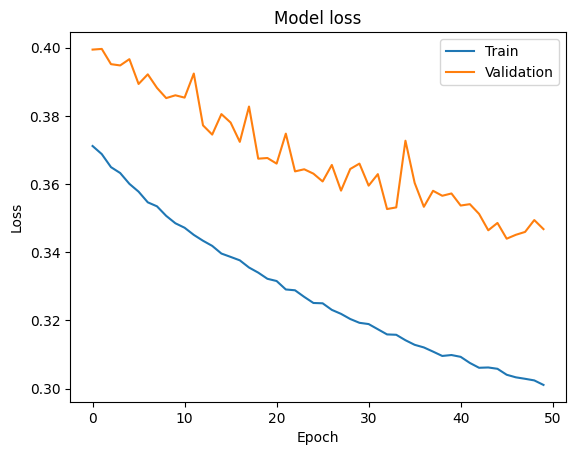

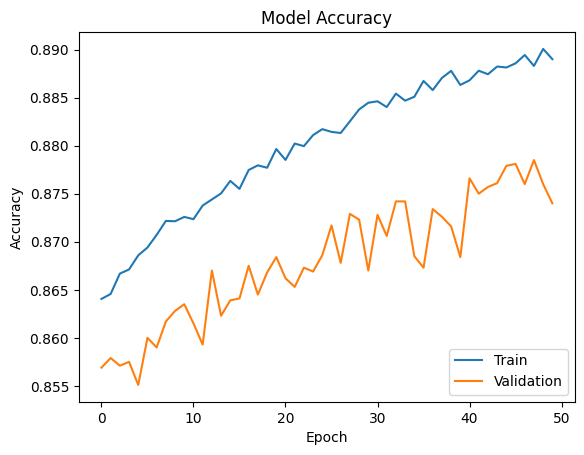

In [90]:
from tensorflow.keras.callbacks import EarlyStopping 
# Define the callback function
early_stopping = EarlyStopping(patience=10)

# train the model and plot the training and testing loss and accuracy at each epoc
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test), 
                    callbacks=[early_stopping])

# Evaluating the model (using Mean Squared Error)
loss = model.evaluate(X_test, y_test, verbose=0)
loss

# Plotting the training and testing loss
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

# plot the accuracy of training and validation

# Plotting the training and validation accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

## Evaluation 

### Current Performance:
The model shows a healthy training trend with accuracy reaching ~89% and loss decreasing to ~0.30. However, the validation curves are notably "noisy" or jagged, indicating instability during the optimization process.

### Observations
`Generalization Gap`: There is a consistent gap between training and validation metrics. While not severe overfitting, the model is struggling to generalize as smoothly as it learns.

`Validation Volatility`: The spikes in the validation loss/accuracy suggest the learning rate might be too high for the final stages of training, causing the optimizer to overshot the global minimum.

`Performance Ceiling`: For Fashion MNIST, a well-tuned CNN typically hits 91–94% accuracy. Current results suggest the model is slightly under-regularized.

### Recommended Improvements
`Learning Rate Decay`: Use a scheduler (like ReduceLROnPlateau) to lower the learning rate when validation loss stalls. This will smooth out the jagged curves.

`Increased Regularization`: * Add Dropout layers (0.25 to 0.5) to reduce the gap between training and validation.

Apply Batch Normalization to stabilize and speed up training.

`Early Stopping`: Implement EarlyStopping monitoring val_loss to prevent the model from learning noise in later epochs.

`Data Augmentation`: Introduce random horizontal flips or slight shifts to improve the model's ability to handle variations in the clothing images